In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("OECD.ENV.EPI,DSD_EWASTE@DF_EWASTE,,complete,2026-10-29 13-20-54.csv")

In [3]:
df.head(5)

,STRUCTURE,STRUCTURE_ID,STRUCTURE_NAME,ACTION,REF_AREA,Reference area,FREQ,Frequency of observation,PRODUCT_CATEGORIES,Product categories,...,TIME_PERIOD,Time period,OBS_VALUE,Observation value,OBS_STATUS,Observation status,UNIT_MULT,Unit multiplier,DECIMALS,Decimals
0,DATAFLOW,OECD.ENV.EPI:DSD_EWASTE@DF_EWASTE(1.0),Waste - Electrical and electronic equipment (e...,I,AUS,Australia,A,Annual,EE6,Total,...,2000,NaN,16.25509,NaN,A,Normal value,0,Units,2,Two
1,DATAFLOW,OECD.ENV.EPI:DSD_EWASTE@DF_EWASTE(1.0),Waste - Electrical and electronic equipment (e...,I,AUS,Australia,A,Annual,EE6,Total,...,2005,NaN,24.44847,NaN,A,Normal value,0,Units,2,Two
2,DATAFLOW,OECD.ENV.EPI:DSD_EWASTE@DF_EWASTE(1.0),Waste - Electrical and electronic equipment (e...,I,AUS,Australia,A,Annual,EE6,Total,...,2010,NaN,30.98496,NaN,A,Normal value,0,Units,2,Two
3,DATAFLOW,OECD.ENV.EPI:DSD_EWASTE@DF_EWASTE(1.0),Waste - Electrical and electronic equipment (e...,I,AUS,Australia,A,Annual,EE6,Total,...,2011,NaN,32.31625,NaN,A,Normal value,0,Units,2,Two
4,DATAFLOW,OECD.ENV.EPI:DSD_EWASTE@DF_EWASTE(1.0),Waste - Electrical and electronic equipment (e...,I,AUS,Australia,A,Annual,EE6,Total,...,2012,NaN,31.90771,NaN,A,Normal value,0,Units,2,Two


In [4]:
df.shape

(14589, 24)

In [5]:
df.columns

Index(['STRUCTURE', 'STRUCTURE_ID', 'STRUCTURE_NAME', 'ACTION', 'REF_AREA',
       'Reference area', 'FREQ', 'Frequency of observation',
       'PRODUCT_CATEGORIES', 'Product categories', 'UNIT_MEASURE',
       'Unit of measure', 'MEASURE', 'Measure', 'TIME_PERIOD', 'Time period',
       'OBS_VALUE', 'Observation value', 'OBS_STATUS', 'Observation status',
       'UNIT_MULT', 'Unit multiplier', 'DECIMALS', 'Decimals'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14589 entries, 0 to 14588
Data columns (total 24 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   STRUCTURE                 14589 non-null  str    
 1   STRUCTURE_ID              14589 non-null  str    
 2   STRUCTURE_NAME            14589 non-null  str    
 3   ACTION                    14589 non-null  str    
 4   REF_AREA                  14589 non-null  str    
 5   Reference area            14589 non-null  str    
 6   FREQ                      14589 non-null  str    
 7   Frequency of observation  14589 non-null  str    
 8   PRODUCT_CATEGORIES        14589 non-null  str    
 9   Product categories        14589 non-null  str    
 10  UNIT_MEASURE              14589 non-null  str    
 11  Unit of measure           14589 non-null  str    
 12  MEASURE                   14589 non-null  str    
 13  Measure                   14589 non-null  str    
 14  TIME_PERIOD      

In [7]:
df.describe()

,TIME_PERIOD,Time period,OBS_VALUE,Observation value,UNIT_MULT,DECIMALS
count,14589.000000,0.0,14589.000000,0.0,14589.000000,14589.0
mean,2018.485297,NaN,91.769969,NaN,1.500720,2.0
std,4.561872,NaN,497.970981,NaN,1.500051,0.0
min,2000.000000,NaN,0.000000,NaN,0.000000,2.0
25%,2017.000000,NaN,1.315809,NaN,0.000000,2.0
50%,2020.000000,NaN,5.732679,NaN,3.000000,2.0
75%,2022.000000,NaN,27.464000,NaN,3.000000,2.0
max,2024.000000,NaN,14502.130000,NaN,3.000000,2.0


In [8]:
waste_df = df[
    (df["Measure"] == "Total waste generated") &
    (df["Product categories"] == "Total") &
    (df["Unit of measure"] == "Tonnes")
].copy()

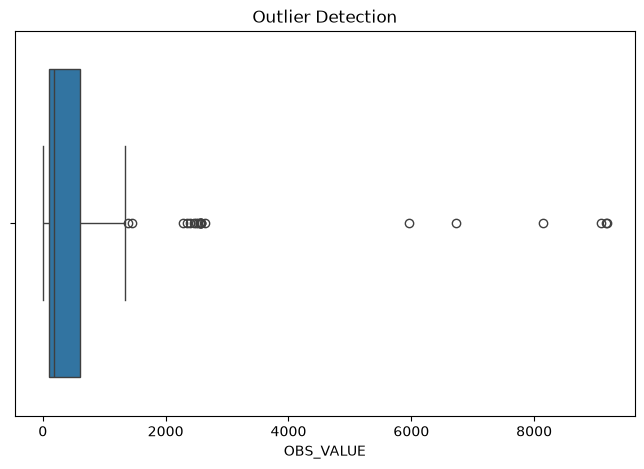

In [9]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=waste_df["OBS_VALUE"])

plt.title("Outlier Detection")
plt.show()

In [10]:
Q1 = waste_df["OBS_VALUE"].quantile(0.25)

Q3 = waste_df["OBS_VALUE"].quantile(0.75)

print("Q1:", Q1)
print("Q3:", Q3)

Q1: 94.53999999999999
Q3: 606.5825


In [11]:
IQR = Q3 - Q1

print("IQR:", IQR)
lower_limit = Q1 - (1.5 * IQR)

upper_limit = Q3 + (1.5 * IQR)

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

IQR: 512.0425
Lower Limit: -673.5237500000001
Upper Limit: 1374.64625


In [12]:
outliers = waste_df[
    (waste_df["OBS_VALUE"] < lower_limit) |
    (waste_df["OBS_VALUE"] > upper_limit)
]

print(outliers)

     STRUCTURE                            STRUCTURE_ID  \
2773  DATAFLOW  OECD.ENV.EPI:DSD_EWASTE@DF_EWASTE(1.0)   
2774  DATAFLOW  OECD.ENV.EPI:DSD_EWASTE@DF_EWASTE(1.0)   
2775  DATAFLOW  OECD.ENV.EPI:DSD_EWASTE@DF_EWASTE(1.0)   
2776  DATAFLOW  OECD.ENV.EPI:DSD_EWASTE@DF_EWASTE(1.0)   
2777  DATAFLOW  OECD.ENV.EPI:DSD_EWASTE@DF_EWASTE(1.0)   
2778  DATAFLOW  OECD.ENV.EPI:DSD_EWASTE@DF_EWASTE(1.0)   
2779  DATAFLOW  OECD.ENV.EPI:DSD_EWASTE@DF_EWASTE(1.0)   
2780  DATAFLOW  OECD.ENV.EPI:DSD_EWASTE@DF_EWASTE(1.0)   
2781  DATAFLOW  OECD.ENV.EPI:DSD_EWASTE@DF_EWASTE(1.0)   
2782  DATAFLOW  OECD.ENV.EPI:DSD_EWASTE@DF_EWASTE(1.0)   
2783  DATAFLOW  OECD.ENV.EPI:DSD_EWASTE@DF_EWASTE(1.0)   
2784  DATAFLOW  OECD.ENV.EPI:DSD_EWASTE@DF_EWASTE(1.0)   
2785  DATAFLOW  OECD.ENV.EPI:DSD_EWASTE@DF_EWASTE(1.0)   
2819  DATAFLOW  OECD.ENV.EPI:DSD_EWASTE@DF_EWASTE(1.0)   
2820  DATAFLOW  OECD.ENV.EPI:DSD_EWASTE@DF_EWASTE(1.0)   
2863  DATAFLOW  OECD.ENV.EPI:DSD_EWASTE@DF_EWASTE(1.0)   
2864  DATAFLOW

In [13]:
print("Number of potential outliers:", len(outliers))

Number of potential outliers: 21


In [14]:
print(outliers[[
    "Reference area",
    "TIME_PERIOD",
    "OBS_VALUE"
]])

     Reference area  TIME_PERIOD    OBS_VALUE
2773          Japan         2010  2285.310552
2774          Japan         2011  2341.664828
2775          Japan         2012  2399.801195
2776          Japan         2013  2453.860138
2777          Japan         2014  2498.411403
2778          Japan         2015  2532.065331
2779          Japan         2016  2552.002507
2780          Japan         2017  2560.100284
2781          Japan         2018  2564.149181
2782          Japan         2019  2568.959087
2783          Japan         2020  2573.910361
2784          Japan         2021  2579.000000
2785          Japan         2022  2638.100000
2819         Mexico         2020  1394.742770
2820         Mexico         2021  1448.391064
2863  United States         2000  5969.275589
2864  United States         2005  6731.310771
2865  United States         2010  8137.447118
2866  United States         2015  9080.919247
2867  United States         2017  9180.709569
2868  United States         2018  

In [15]:
print(outliers[[
    "Reference area",
    "TIME_PERIOD",
    "Measure",
    "Product categories",
    "Unit of measure",
    "OBS_VALUE"
]])

     Reference area  TIME_PERIOD                Measure Product categories  \
2773          Japan         2010  Total waste generated              Total   
2774          Japan         2011  Total waste generated              Total   
2775          Japan         2012  Total waste generated              Total   
2776          Japan         2013  Total waste generated              Total   
2777          Japan         2014  Total waste generated              Total   
2778          Japan         2015  Total waste generated              Total   
2779          Japan         2016  Total waste generated              Total   
2780          Japan         2017  Total waste generated              Total   
2781          Japan         2018  Total waste generated              Total   
2782          Japan         2019  Total waste generated              Total   
2783          Japan         2020  Total waste generated              Total   
2784          Japan         2021  Total waste generated         

In [16]:
df.isnull().sum()

STRUCTURE                       0
STRUCTURE_ID                    0
STRUCTURE_NAME                  0
ACTION                          0
REF_AREA                        0
Reference area                  0
FREQ                            0
Frequency of observation        0
PRODUCT_CATEGORIES              0
Product categories              0
UNIT_MEASURE                    0
Unit of measure                 0
MEASURE                         0
Measure                         0
TIME_PERIOD                     0
Time period                 14589
OBS_VALUE                       0
Observation value           14589
OBS_STATUS                      0
Observation status              0
UNIT_MULT                       0
Unit multiplier                 0
DECIMALS                        0
Decimals                        0
dtype: int64

In [17]:
df.isnull().sum().sum()

np.int64(29178)

In [18]:
df = df.drop(columns=["Time period", "Observation value"])

In [19]:
df.isnull().sum()

STRUCTURE                   0
STRUCTURE_ID                0
STRUCTURE_NAME              0
ACTION                      0
REF_AREA                    0
Reference area              0
FREQ                        0
Frequency of observation    0
PRODUCT_CATEGORIES          0
Product categories          0
UNIT_MEASURE                0
Unit of measure             0
MEASURE                     0
Measure                     0
TIME_PERIOD                 0
OBS_VALUE                   0
OBS_STATUS                  0
Observation status          0
UNIT_MULT                   0
Unit multiplier             0
DECIMALS                    0
Decimals                    0
dtype: int64

In [20]:
df.duplicated().sum()

np.int64(0)

In [21]:
df.dtypes

STRUCTURE                       str
STRUCTURE_ID                    str
STRUCTURE_NAME                  str
ACTION                          str
REF_AREA                        str
Reference area                  str
FREQ                            str
Frequency of observation        str
PRODUCT_CATEGORIES              str
Product categories              str
UNIT_MEASURE                    str
Unit of measure                 str
MEASURE                         str
Measure                         str
TIME_PERIOD                   int64
OBS_VALUE                   float64
OBS_STATUS                      str
Observation status              str
UNIT_MULT                     int64
Unit multiplier                 str
DECIMALS                      int64
Decimals                        str
dtype: object

In [22]:
df.describe()

,TIME_PERIOD,OBS_VALUE,UNIT_MULT,DECIMALS
count,14589.000000,14589.000000,14589.000000,14589.0
mean,2018.485297,91.769969,1.500720,2.0
std,4.561872,497.970981,1.500051,0.0
min,2000.000000,0.000000,0.000000,2.0
25%,2017.000000,1.315809,0.000000,2.0
50%,2020.000000,5.732679,3.000000,2.0
75%,2022.000000,27.464000,3.000000,2.0
max,2024.000000,14502.130000,3.000000,2.0


In [23]:
df["Measure"].value_counts()

Measure
Products put on the market    4254
Waste collected               4056
Total waste generated         3190
Recycling                     3082
Reused and remanufactured        7
Name: count, dtype: int64

In [24]:
df["Product categories"].value_counts()

Product categories
Total                                            3343
Large equipment                                  1711
Small equipment                                  1631
Temperature exchange equipment                   1627
Small IT and telecommunication equipment         1595
Screens and monitors                             1593
Lamps                                            1561
Large equipment excluding photovoltaic panels     814
Photovoltaic panels                               714
Name: count, dtype: int64

In [25]:
df["Unit of measure"].value_counts()

Unit of measure
Tonnes                    7298
Kilogrammes per person    7291
Name: count, dtype: int64

In [26]:
df.columns

Index(['STRUCTURE', 'STRUCTURE_ID', 'STRUCTURE_NAME', 'ACTION', 'REF_AREA',
       'Reference area', 'FREQ', 'Frequency of observation',
       'PRODUCT_CATEGORIES', 'Product categories', 'UNIT_MEASURE',
       'Unit of measure', 'MEASURE', 'Measure', 'TIME_PERIOD', 'OBS_VALUE',
       'OBS_STATUS', 'Observation status', 'UNIT_MULT', 'Unit multiplier',
       'DECIMALS', 'Decimals'],
      dtype='str')

In [27]:
df.select_dtypes(include="object").columns

C:\Users\HP\AppData\Local\Temp\ipykernel_3040\1196084386.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(include="object").columns


Index(['STRUCTURE', 'STRUCTURE_ID', 'STRUCTURE_NAME', 'ACTION', 'REF_AREA',
       'Reference area', 'FREQ', 'Frequency of observation',
       'PRODUCT_CATEGORIES', 'Product categories', 'UNIT_MEASURE',
       'Unit of measure', 'MEASURE', 'Measure', 'OBS_STATUS',
       'Observation status', 'Unit multiplier', 'Decimals'],
      dtype='str')

In [28]:
df["Reference area"].nunique()

47

In [29]:
df["Reference area"].value_counts().head(10)

Reference area
Switzerland    788
Costa Rica     595
Japan          438
Australia      420
Israel         420
Hungary        418
Luxembourg     414
Poland         400
Cyprus         392
Finland        380
Name: count, dtype: int64

In [30]:
waste_df = df[
    (df["Measure"] == "Total waste generated") &
    (df["Product categories"] == "Total") &
    (df["Unit of measure"] == "Tonnes")
].copy()

In [31]:
X = waste_df[["TIME_PERIOD", "Reference area"]]

y = waste_df["OBS_VALUE"]

In [32]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 188
Testing rows: 48


In [33]:
from sklearn.preprocessing import OneHotEncoder

In [34]:
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False,
    drop="first"
)

In [35]:
train_encoded = encoder.fit_transform(X_train[["Reference area"]])
test_encoded = encoder.transform(X_test[["Reference area"]])

In [36]:
train_country = pd.DataFrame(
    train_encoded,
    columns=encoder.get_feature_names_out(["Reference area"]),
    index=X_train.index
)

test_country = pd.DataFrame(
    test_encoded,
    columns=encoder.get_feature_names_out(["Reference area"]),
    index=X_test.index
)

In [37]:
X_train_encoded = pd.concat(
    [X_train[["TIME_PERIOD"]], train_country], axis=1
)

X_test_encoded = pd.concat(
    [X_test[["TIME_PERIOD"]], test_country], axis=1
)

In [38]:
print("Training shape:", X_train_encoded.shape)
print("Testing shape:", X_test_encoded.shape)

Training shape: (188, 27)
Testing shape: (48, 27)


In [39]:
print("Training shape:", X_train_encoded.shape)
print("Testing shape:", X_test_encoded.shape)

Training shape: (188, 27)
Testing shape: (48, 27)


In [40]:
from sklearn.preprocessing import StandardScaler

In [41]:
scaler = StandardScaler()

In [42]:
X_train_scaled = scaler.fit_transform(X_train_encoded)

X_test_scaled = scaler.transform(X_test_encoded)

In [43]:
print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

Training shape: (188, 27)
Testing shape: (48, 27)


In [44]:
len(X_test)

48

In [45]:
len(y_test)

48

In [51]:
from sklearn.linear_model import LinearRegression
lr_model = LinearRegression()

In [52]:
lr_model.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](27,)","[ 141.39, -47.42, -80.14,..., -58.29, -68.35,1213.27]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,616.2
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,27
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,27
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](27,)","[16.85,14.25,14.24,...,13.75, 9.93, 3.65]"


In [53]:
lr_pred = lr_model.predict(X_test_scaled)

In [54]:
comparison = pd.DataFrame({
    "Actual E-Waste": y_test.values,
    "Predicted E-Waste": lr_pred
})

comparison.head(10)

,Actual E-Waste,Predicted E-Waste
0,64.964918,82.875970
1,194.300000,283.770281
2,144.440000,56.041911
3,477.499199,471.625584
4,776.180000,745.523671
5,2498.411403,2447.117590
6,7.200000,-3.801261
7,82.840000,-18.563090
8,1337.762118,1155.385016
9,306.300000,270.205241


In [56]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

In [57]:
lr_mae = mean_absolute_error(y_test, lr_pred)

lr_mse = mean_squared_error(y_test, lr_pred)

lr_rmse = np.sqrt(lr_mse)

lr_r2 = r2_score(y_test, lr_pred)

print(f"MAE={lr_mae:5.2f} MSE={lr_mse:5.2f} RMSE={lr_rmse:5.2f} R**2={lr_r2:.3f}")

MAE=79.09 MSE=32517.73 RMSE=180.33 R**2=0.983


In [58]:
from sklearn.ensemble import RandomForestRegressor

In [59]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

In [60]:
rf_model.fit(X_train_encoded, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [61]:
rf_pred = rf_model.predict(X_test_encoded)

In [62]:
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_mse = mean_squared_error(y_test, rf_pred)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_pred)

print(f"MAE={rf_mae:5.2f} MSE={rf_mse:5.2f} RMSE={rf_rmse:5.2f} R**2={rf_r2:.3f}")

MAE=44.16 MSE=6231.78 RMSE=78.94 R**2=0.997


In [63]:
from sklearn.tree import DecisionTreeRegressor

In [64]:
dt_model = DecisionTreeRegressor(random_state=42)

In [65]:
dt_model.fit(X_train_encoded, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with

In [66]:
dt_pred = dt_model.predict(X_test_encoded)

In [67]:
dt_mae = mean_absolute_error(y_test, dt_pred)
dt_mse = mean_squared_error(y_test, dt_pred)
dt_rmse = np.sqrt(dt_mse)
dt_r2 = r2_score(y_test, dt_pred)

print(f"MAE={dt_mae:5.2f} MSE={dt_mse:5.2f} RMSE={dt_rmse:5.2f} R**2={dt_r2:.3f}")

MAE=34.47 MSE=4154.70 RMSE=64.46 R**2=0.998


In [68]:
lr_model = LinearRegression()

lr_model.fit(X_train_scaled, y_train)

lr_pred = lr_model.predict(X_test_scaled)

In [69]:
lr_mae = mean_absolute_error(y_test, lr_pred)
lr_mse = mean_squared_error(y_test, lr_pred)
lr_rmse = np.sqrt(lr_mse)
lr_r2 = r2_score(y_test, lr_pred)

print(f"MAE={lr_mae:5.2f} MSE={lr_mse:5.2f} RMSE={lr_rmse:5.2f} R**2={lr_r2:.3f}")

MAE=79.09 MSE=32517.73 RMSE=180.33 R**2=0.983


In [70]:
print("Training year range:",
      X_train["TIME_PERIOD"].min(),
      "-", X_train["TIME_PERIOD"].max())

print("Testing year range:",
      X_test["TIME_PERIOD"].min(),
      "-", X_test["TIME_PERIOD"].max())

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Training year range: 2000 - 2024
Testing year range: 2000 - 2024
Training shape: (188, 2)
Testing shape: (48, 2)
Scaled training shape: (188, 27)
Scaled testing shape: (48, 27)


In [71]:
sorted(waste_df["TIME_PERIOD"].unique())

[np.int64(2000),
 np.int64(2005),
 np.int64(2010),
 np.int64(2011),
 np.int64(2012),
 np.int64(2013),
 np.int64(2014),
 np.int64(2015),
 np.int64(2016),
 np.int64(2017),
 np.int64(2018),
 np.int64(2019),
 np.int64(2020),
 np.int64(2021),
 np.int64(2022),
 np.int64(2023),
 np.int64(2024)]

In [72]:
##K-FOLD CROSS VALIDATION

In [80]:
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression

In [82]:
kfold = KFold(n_splits=10, shuffle=True, random_state=42)

model = LinearRegression()

results = cross_val_score(
    model,
    X_train_encoded,
    y_train,
    scoring="neg_mean_absolute_error",
    cv=kfold
)

print(-results)
print("Average MAE:", -results.mean())

[157.05403851  38.74238687  63.69035717  69.83995817 152.0838396
  70.61683555 120.84285385 123.58605003 123.15121236 149.51794147]
Average MAE: 106.91254735689931


In [83]:
###HYPER PARAMETER TUNING USING GRIDSEARCHCV

In [85]:
from sklearn.model_selection import GridSearchCV

In [91]:


param_grid = {
    'fit_intercept': [True, False]
}

n_folds = 5

model = LinearRegression()

grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=n_folds
)

grid_search.fit(X_train_scaled, y_train)

grid_search.best_score_

grid_search.best_params_

{'fit_intercept': True}

In [92]:
grid_search.best_score_

np.float64(0.9476168353177732)

In [93]:
grid_search.best_params_

{'fit_intercept': True}

In [94]:
y_pred = grid_search.predict(X_test_scaled)

In [95]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 79.0896451045552
MSE: 32517.734977191907
RMSE: 180.32674504130526
R2 Score: 0.9831791985891974


In [ ]:
### predicting future e waste generation for mexico

In [112]:
X = waste_df[["TIME_PERIOD", "Reference area"]]
y = waste_df["OBS_VALUE"]

In [113]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False, drop="first")

X_country = encoder.fit_transform(X[["Reference area"]])

country_df = pd.DataFrame(
    X_country,
    columns=encoder.get_feature_names_out(["Reference area"]),
    index=X.index
)

X = pd.concat([X[["TIME_PERIOD"]], country_df], axis=1)

In [114]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [115]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_scaled, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](27,)","[ 142.49, -42.84, -78.87,..., -61.71, -81.09,1216.99]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,628.3
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,27
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,27
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](27,)","[18.78,15.94,15.91,...,15.39,11.26, 3.95]"


In [116]:
future_data = pd.DataFrame({
    "TIME_PERIOD": [2025],
    "Reference area": ["Mexico"]
})

future_country = encoder.transform(future_data[["Reference area"]])

future_country_df = pd.DataFrame(
    future_country,
    columns=encoder.get_feature_names_out(["Reference area"])
)

future_X = pd.concat(
    [future_data[["TIME_PERIOD"]].reset_index(drop=True),
     future_country_df.reset_index(drop=True)],
    axis=1
)

future_X_scaled = scaler.transform(future_X)

In [117]:
y_pred = model.predict(future_X_scaled)

print("Predicted e-waste generation in Mexico for 2025:")
print(y_pred)

Predicted e-waste generation in Mexico for 2025:
[1319.55742377]


In [118]:
# Filter Australia data
mexico_data = waste_df[waste_df["Reference area"] == "Mexico"]

# Sort by year
mexico_data = mexico_data.sort_values("TIME_PERIOD")

# Display actual e-waste generation
print(mexico_data[["TIME_PERIOD", "OBS_VALUE"]])

      TIME_PERIOD    OBS_VALUE
2807         2000   408.402508
2808         2005   557.845874
2809         2010   787.469783
2810         2011   843.226281
2811         2012   902.850212
2812         2013   962.149450
2813         2014  1021.301709
2814         2015  1081.131704
2815         2016  1142.993730
2816         2017  1207.719049
2817         2018  1274.386923
2818         2019  1337.762118
2819         2020  1394.742770
2820         2021  1448.391064
2821         2022  1265.128213
2822         2023  1249.186667
2823         2024  1268.299223


In [119]:
print("Future Year: 2025")
print("Country: Mexico")
print("Predicted E-waste Generation:", y_pred[0])

Future Year: 2025
Country: Mexico
Predicted E-waste Generation: 1319.5574237673527


In [110]:
data_2024 = waste_df[waste_df["TIME_PERIOD"] == 2024]

print(data_2024[["Reference area", "TIME_PERIOD", "OBS_VALUE"]])

     Reference area  TIME_PERIOD    OBS_VALUE
2713          Chile         2024   230.000000
2743     Costa Rica         2024    56.661214
2823         Mexico         2024  1268.299223


In [111]:
mexico_data = waste_df[waste_df["Reference area"] == "Mexico"]

mexico_data = mexico_data.sort_values("TIME_PERIOD")

print(mexico_data[["TIME_PERIOD", "OBS_VALUE"]])

      TIME_PERIOD    OBS_VALUE
2807         2000   408.402508
2808         2005   557.845874
2809         2010   787.469783
2810         2011   843.226281
2811         2012   902.850212
2812         2013   962.149450
2813         2014  1021.301709
2814         2015  1081.131704
2815         2016  1142.993730
2816         2017  1207.719049
2817         2018  1274.386923
2818         2019  1337.762118
2819         2020  1394.742770
2820         2021  1448.391064
2821         2022  1265.128213
2822         2023  1249.186667
2823         2024  1268.299223


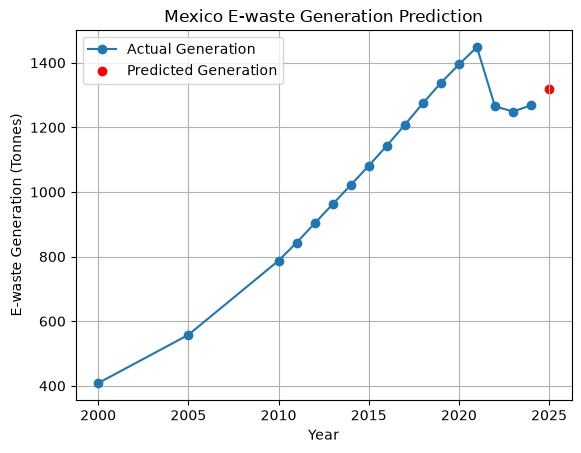

In [120]:
import matplotlib.pyplot as plt

# Actual Mexico data
plt.plot(mexico_data["TIME_PERIOD"], mexico_data["OBS_VALUE"], marker='o', label="Actual Generation")

# Predicted 2025 value
plt.scatter(2025, y_pred[0], color='red', label="Predicted Generation")

plt.xlabel("Year")
plt.ylabel("E-waste Generation (Tonnes)")
plt.title("Mexico E-waste Generation Prediction")

plt.legend()
plt.grid()

plt.show()

In [97]:

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
import pandas as pd

# 1. Select all historical data
X_all = waste_df[["TIME_PERIOD", "Reference area"]]
y_all = waste_df["OBS_VALUE"]

# 2. Convert country names into numerical values
future_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False,
    drop="first"
)

country_encoded = future_encoder.fit_transform(
    X_all[["Reference area"]]
)

country_df = pd.DataFrame(
    country_encoded,
    columns=future_encoder.get_feature_names_out(["Reference area"]),
    index=X_all.index
)

# 3. Combine year and encoded country columns
X_all_encoded = pd.concat(
    [X_all[["TIME_PERIOD"]], country_df],
    axis=1
)

# 4. Scale the input data
future_scaler = StandardScaler()

X_all_scaled = future_scaler.fit_transform(X_all_encoded)

# 5. Train the final Linear Regression model
final_model = LinearRegression(**grid_search.best_params_)

final_model.fit(X_all_scaled, y_all)

print("Final Linear Regression model trained successfully!")
print("Training records:", len(X_all))


Final Linear Regression model trained successfully!
Training records: 236


In [98]:

# Select country and future year
future_input = pd.DataFrame({
    "TIME_PERIOD": [2025],
    "Reference area": ["India"]
})

# Encode the country using the existing encoder
country_encoded = future_encoder.transform(
    future_input[["Reference area"]]
)

country_df = pd.DataFrame(
    country_encoded,
    columns=future_encoder.get_feature_names_out(["Reference area"])
)

# Combine year and country
future_input_encoded = pd.concat(
    [future_input[["TIME_PERIOD"]].reset_index(drop=True),
     country_df.reset_index(drop=True)],
    axis=1
)

# Apply the existing scaler
future_input_scaled = future_scaler.transform(
    future_input_encoded
)

# Predict e-waste generation
prediction_2025 = final_model.predict(future_input_scaled)

print("Country: India")
print("Year: 2025")
print("Predicted e-waste generation:", prediction_2025[0])


Country: India
Year: 2025
Predicted e-waste generation: 681.193806095916


C:\Users\HP\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


In [100]:

# Get Australia's historical e-waste records
australia_data = waste_df[
    waste_df["Reference area"] == "Australia"
].sort_values("TIME_PERIOD")

# Display year and e-waste generation
print(australia_data[["TIME_PERIOD", "OBS_VALUE"]])



      TIME_PERIOD   OBS_VALUE
2668         2000   86.000000
2669         2005  169.992034
2670         2010  297.192882
2671         2011  326.811326
2672         2012  356.381585
2673         2013  384.521103
2674         2014  410.838872
2675         2015  435.036793
2676         2016  457.411554
2677         2017  477.499199
2678         2018  495.630807
2679         2019  510.598570
2680         2020  525.013328
2681         2021  537.730000
2682         2022  545.569000


In [101]:

# Select country and future year
future_input = pd.DataFrame({
    "TIME_PERIOD": [2025],
    "Reference area": ["Australia"]
})

# Encode country
country_encoded = future_encoder.transform(
    future_input[["Reference area"]]
)

country_df = pd.DataFrame(
    country_encoded,
    columns=future_encoder.get_feature_names_out(["Reference area"])
)

# Combine year and country
future_input_encoded = pd.concat(
    [future_input[["TIME_PERIOD"]].reset_index(drop=True),
     country_df.reset_index(drop=True)],
    axis=1
)

# Scale input
future_input_scaled = future_scaler.transform(
    future_input_encoded
)

# Predict future e-waste generation
prediction_2025 = final_model.predict(future_input_scaled)

print("Country: Australia")
print("Year: 2025")
print("Predicted e-waste generation:", prediction_2025[0])


Country: Australia
Year: 2025
Predicted e-waste generation: 681.193806095916
